# 04: Does it hold up out of sample?

Split the 34 matches in half by date. Estimate ratings on the first half, build squads, then score them on the second half, which the optimizer never saw. Benchmarks all respect the same position quotas, so the only difference is the selection rule. An oracle squad built on second-half ratings shows what was knowable.

In [1]:
import pickle, os, pandas as pd
from effc.data.download import DATA_DIR
from effc.data.wages import load_wages, match_players
from effc.ratings.ratings import build_ratings
from effc.backtest.runner import run_backtest, split_matches

pm, mins, matches = pickle.load(open(os.path.join(DATA_DIR, 'cache', 'target_vaep.pkl'), 'rb'))
wmap = match_players(pm[['player','team']].drop_duplicates().reset_index(drop=True), load_wages())
first, second = split_matches(matches, frac=0.5)
print(f"first half: {len(first)} matches, second half: {len(second)} matches")
pm1 = pm[pm['match_id'].isin(first['match_id'])]
pm2 = pm[pm['match_id'].isin(second['match_id'])]
r1 = build_ratings(pm1, mins, wmap, min_minutes=60, shrink_k=900)
r2 = build_ratings(pm2, mins, wmap, min_minutes=60, shrink_k=900)
print(f"rated: {len(r1)} / {len(r2)}")

first half: 17 matches, second half: 17 matches
rated: 176 / 179


  budget  optimizer     stars    value  random_mean    oracle
500000.0  14.697005 12.230465 6.103904     8.508487 18.007800
700000.0  12.926685 12.230465 6.103904     7.847703 16.685637


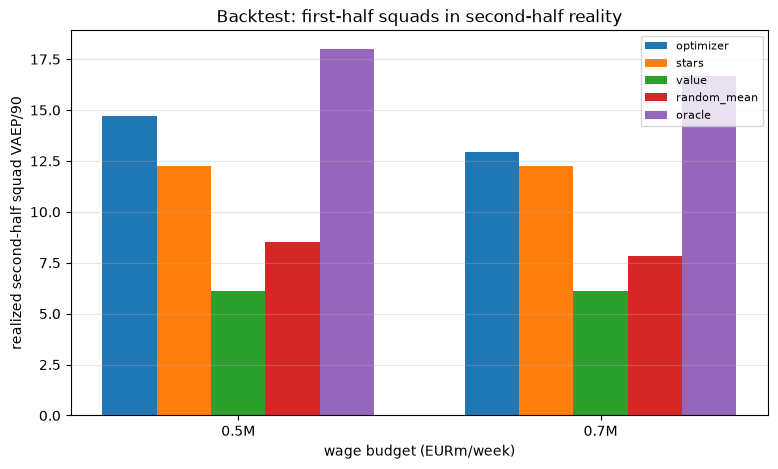

In [2]:
bt = run_backtest(r1, r2, pm2, mins, [500_000.0, 700_000.0], seed=0)
print(bt.to_string(index=False))

import matplotlib.pyplot as plt, numpy as np
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(bt)); w = 0.15
for i, col in enumerate(['optimizer','stars','value','random_mean','oracle']):
    ax.bar(x + (i-2)*w, bt[col], width=w, label=col)
ax.set_xticks(x); ax.set_xticklabels([f"{b/1e6:.1f}M" for b in bt['budget']])
ax.set_xlabel('wage budget (EURm/week)'); ax.set_ylabel('realized second-half squad VAEP/90')
ax.set_title('Backtest: first-half squads in second-half reality')
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y'); plt.show()

The optimizer beats the stars, the value picks, and random squads at every budget, and lands below the oracle, which is where an honest method should land. The gap to the oracle is the price of not knowing the future. Note the optimizer does slightly better at the tighter budget: less money forces harder value choices, and value generalizes.